# 베이스라인 — 기상만으로 예측 (6_기상만)

CLAUDE.md 베이스라인 목록의 "기상만으로 예측". 기상·대기 칼럼만 알 때 검출을 얼마나 가려낼 수 있는지 잰다.

| 항목 | 내용 |
|---|---|
| 입력 | `data/X.parquet`(행 키·기준일만 — 분할용), `data/y.parquet`, 기상·대기 조인 결과 `data/collected/exp1_wx/wx_<변수>.parquet` 17개(`3_기상조인_후_학습.ipynb` 4절에서 만듦) |
| 피처 | 기상·대기 17변수 × D-1~D-100 = **1,700칼럼만**. LIMS 칼럼(`2_바로학습` 의 피처 5개)과 식품 칼럼은 넣지 않는다 |
| 방법 | XGBoost·LightGBM·CatBoost 기본 하이퍼파라미터, seed 42 — `2_바로학습`·`3_기상조인_후_학습` 과 같은 인자 |
| 장치 | XGBoost GPU · LightGBM CPU · CatBoost GPU (`3_기상조인_후_학습` 과 같음) |
| 분할·임계값·지표 | `2_바로학습` 과 같음 — train ~2024-06-30 · val 2024-07-01~2025-06-30(임계값 고르기에만) · test 2025-07-01~2026-06-30, 임계값 0.5·val F1최대·val F2최대 |
| 결과 기록 | MLflow 실험 `리스테리아_EXP1` 의 run `6_기상만` (9절). 파일로 따로 저장하지 않는다 |

> **왜 `4_월만`·`5_품목만` 처럼 비율표가 아닌가**: 그 둘은 입력이 칼럼 하나라 "값별 검출 비율표"가 곧 모델이었다. 기상은 연속값 칼럼이 1,700개라 그런 표를 만들 수 없어, `2_바로학습`·`3_기상조인_후_학습` 과 같은 모델 3개를 기본값으로 쓴다. 세 실험은 **입력 칼럼만 다르다**: `2_바로학습` = LIMS 5칼럼, `6_기상만` = 기상·대기 1,700칼럼, `3_기상조인_후_학습` = 둘 다 + 식품 3칼럼.
>
> **주의**
> - 기상·대기 값은 국내 행이 가까운 관측소 3곳 평균, 해외 행이 해외 제조업소 좌표 값이다(조인 규칙은 `3_기상조인_후_학습` 4절). 해외 행은 기온 3개·강수·일사량만 값이 있고 나머지 칼럼은 결측이다.
> - "기상" 묶음에는 에어코리아 대기오염 3개(이산화질소·일산화탄소·아황산가스)도 들어 있다(3_기상조인에서 붙인 17변수 그대로).
> - 기준일 `mnfctur_de` 는 행마다 제조일·의뢰일·선적일 중 하나(`date_basis`)라, "D-1" 의 뜻도 행마다 다르다.

## 1. 설정

경로·seed·장치·분할 날짜·MLflow 기록 위치. `LOG_TO_MLFLOW` 가 `False` 면 9절에서 기록하지 않고 출력만 본다(다시 실행해도 같은 run 이 쌓이지 않게 — `4_월만`·`5_품목만` 과 같은 방식).

In [1]:
import gc
import json
import logging
import os
import sys
import tempfile
import time
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter
import sklearn
import xgboost as xgb
import lightgbm as lgb
import catboost as cb
os.environ.setdefault('MLFLOW_DISABLE_AGENT_HINT', '1')
import mlflow
from dotenv import dotenv_values
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, average_precision_score, confusion_matrix, precision_recall_curve,
)

SEED = 42
DEVICE = {'XGBoost': 'cuda', 'LightGBM': 'cpu', 'CatBoost': 'GPU'}   # 3_기상조인_후_학습 과 같음

TRAIN_END = '2024-06-30'
VAL_START, VAL_END = '2024-07-01', '2025-06-30'
TEST_START, TEST_END = '2025-07-01', '2026-06-30'
KEY_COL, DATE_COL = 'lims_data_key', 'mnfctur_de'

PROJECT_DIR = Path(r'C:\Users\NT751\Desktop\천영진\리스테리아ML')
ENV_PATH = PROJECT_DIR / '.env'
X_path = PROJECT_DIR / 'data' / 'X.parquet'
y_path = PROJECT_DIR / 'data' / 'y.parquet'
JOIN_DIR = PROJECT_DIR / 'data' / 'collected' / 'exp1_wx'   # 3_기상조인_후_학습 4절에서 만든 조인 결과
LAG_DAYS = 100

# 기상·대기 17변수 (칼럼 이름, 한글 이름) — 3_기상조인_후_학습 4-1절과 같은 순서
WX_VARS = [('avg_temp', '평균기온'), ('max_temp', '최고기온'), ('min_temp', '최저기온'), ('rain', '강수량'),
           ('avg_wind', '평균풍속'), ('max_wind', '최대풍속'), ('sunshine', '일조시간'), ('solar_rad', '일사량'),
           ('soil_t5', '지중온도 5cm'), ('soil_t10', '지중온도 10cm'), ('soil_t20', '지중온도 20cm'),
           ('soil_t30', '지중온도 30cm'), ('soil_t_nas', '지중온도(NAS)'), ('soil_moist', '토양수분'),
           ('no2', '이산화질소'), ('co', '일산화탄소'), ('so2', '아황산가스')]
FEATURES = [f'{v}_d{k:03d}' for v, _ in WX_VARS for k in range(1, LAG_DAYS + 1)]

MLFLOW_URI = dotenv_values(ENV_PATH).get('AFLA_MLFLOW_URI')
assert MLFLOW_URI, '.env 에 AFLA_MLFLOW_URI 가 없음'
if MLFLOW_URI.startswith('sqlite:///') and not Path(MLFLOW_URI.removeprefix('sqlite:///')).is_absolute():
    MLFLOW_URI = 'sqlite:///' + (PROJECT_DIR / MLFLOW_URI.removeprefix('sqlite:///')).as_posix()
MLFLOW_ARTIFACTS = PROJECT_DIR / 'mlruns'
MLFLOW_EXPERIMENT = '리스테리아_EXP1'
RUN_NAME = '6_기상만'
LOG_TO_MLFLOW = False  # 2026-10-01 run 6_기상만 기록함. 다시 기록할 때만 True (실행할 때마다 새 run 이 쌓임)

logging.getLogger('alembic').setLevel(logging.WARNING)
mlflow.set_tracking_uri(MLFLOW_URI)
if mlflow.get_experiment_by_name(MLFLOW_EXPERIMENT) is None:
    mlflow.create_experiment(MLFLOW_EXPERIMENT, artifact_location=MLFLOW_ARTIFACTS.as_uri())
mlflow.set_experiment(MLFLOW_EXPERIMENT)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
warnings.filterwarnings('ignore', message='.*Falling back to prediction using DMatrix')

missing = [v for v, _ in WX_VARS if not (JOIN_DIR / f'wx_{v}.parquet').exists()]
assert not missing, f'조인 파일 없음 {missing} — 3_기상조인_후_학습.ipynb 를 먼저 실행'
print('장치:', DEVICE, '| 피처', len(FEATURES), '| MLflow run', RUN_NAME, '| 기록', LOG_TO_MLFLOW)

장치: {'XGBoost': 'cuda', 'LightGBM': 'cpu', 'CatBoost': 'GPU'} | 피처 1700 | MLflow run 6_기상만 | 기록 True


## 2. 데이터 불러오기와 분할

X 에서는 행 키와 기준일만 읽는다(분할용). y 는 `lims_data_key` 로 X 의 행 순서에 맞춘다. 분할은 `2_바로학습` 과 같다.

In [2]:
X = pd.read_parquet(X_path, columns=[KEY_COL, DATE_COL, 'src_route'])
y_df = pd.read_parquet(y_path)
assert y_df[KEY_COL].is_unique and X[KEY_COL].is_unique
y = y_df.set_index(KEY_COL)['judge_result'].reindex(X[KEY_COL]).set_axis(X.index)
assert y.notna().all()

d = X[DATE_COL]
masks = {
    'train': d <= pd.Timestamp(TRAIN_END),
    'val':   d.between(pd.Timestamp(VAL_START), pd.Timestamp(VAL_END)),
    'test':  d.between(pd.Timestamp(TEST_START), pd.Timestamp(TEST_END)),
}
n_assigned = sum(m.astype(int) for m in masks.values())
assert n_assigned.max() == 1 and n_assigned.min() == 1
split_summary = pd.DataFrame([
    {'구간': s, '시작일': d[m].min().date(), '종료일': d[m].max().date(),
     '행 수': int(m.sum()), '검출(1)': int(y[m].sum()), '검출 비율(%)': round(y[m].mean() * 100, 3)}
    for s, m in masks.items()])
display(split_summary)
SPLITS = ['train', 'val', 'test']
ROWS = {s: np.nonzero(masks[s].to_numpy())[0] for s in SPLITS}
ys = {s: y.iloc[ROWS[s]] for s in SPLITS}

,구간,시작일,종료일,행 수,검출(1),검출 비율(%)
0,train,2015-04-07,2024-06-30,497896,1491,0.299
1,val,2024-07-01,2025-06-30,87553,191,0.218
2,test,2025-07-01,2026-06-30,91088,287,0.315


## 3. 입력 준비 — 기상·대기 1,700칼럼

조인 파일은 모두 X 와 같은 행 순서다(행 키로 확인). 구간마다 float32 배열 하나로 읽는다(`3_기상조인_후_학습` 8절과 같은 방식, 결측은 NaN 그대로). 범주형 칼럼이 없어 모델에 범주형 표시를 하지 않는다.

In [3]:
keys = X[KEY_COL].astype(str).to_numpy()
for v, _ in WX_VARS:
    assert (pq.read_table(JOIN_DIR / f'wx_{v}.parquet', columns=[KEY_COL]).column(0).to_numpy() == keys).all(), v

def build_matrix(rows):
    A = np.empty((len(rows), len(FEATURES)), dtype=np.float32)
    j = 0
    for v, _ in WX_VARS:
        t = pq.read_table(JOIN_DIR / f'wx_{v}.parquet', columns=[f'{v}_d{k:03d}' for k in range(1, LAG_DAYS + 1)])
        for col in t.columns:
            A[:, j] = col.to_numpy()[rows]
            j += 1
        del t
    return A

t0 = time.time()
A_train = build_matrix(ROWS['train'])
print(f'train 입력 {A_train.shape} · {A_train.nbytes / 1e9:.1f}GB · {time.time() - t0:.0f}초')
nan_rate = pd.Series(np.isnan(A_train).mean(axis=0), index=FEATURES)
print('train 결측 비율(칼럼 평균):', {v: round(float(nan_rate[[f'{v}_d{k:03d}' for k in range(1, LAG_DAYS + 1)]].mean()) * 100, 2) for v, _ in WX_VARS})

train 입력 (497896, 1700) · 3.4GB · 14초


train 결측 비율(칼럼 평균): {'avg_temp': 0.0, 'max_temp': 0.0, 'min_temp': 0.0, 'rain': 0.08, 'avg_wind': 7.82, 'max_wind': 7.82, 'sunshine': 7.82, 'solar_rad': 0.0, 'soil_t5': 7.82, 'soil_t10': 7.82, 'soil_t20': 7.82, 'soil_t30': 7.82, 'soil_t_nas': 7.91, 'soil_moist': 7.91, 'no2': 7.82, 'co': 7.82, 'so2': 7.82}


## 4. 학습 — 기본 하이퍼파라미터 (2_바로학습·3_기상조인과 같은 인자)

튜닝·불균형 보정·조기 종료 없음. 순서는 CatBoost(GPU) → XGBoost(GPU) → LightGBM (`3_기상조인_후_학습` 과 같은 이유 — CatBoost 가 GPU 메모리를 거의 다 잡음). 모델끼리 독립이라 순서는 결과에 영향이 없다.

In [4]:
models, fit_seconds = {}, {}

def key_params(name, model):
    if name == 'XGBoost':
        tp = json.loads(model.get_booster().save_config())['learner']['gradient_booster']['tree_train_param']
        return {'트리 수': model.get_booster().num_boosted_rounds(), '최대 깊이': int(tp['max_depth']), '학습률': round(float(tp['eta']), 4)}
    if name == 'LightGBM':
        p = model.get_params()
        return {'트리 수': p['n_estimators'], '잎 수': p['num_leaves'], '학습률': p['learning_rate']}
    p = model.get_all_params()
    return {'트리 수': p['iterations'], '깊이': p['depth'], '학습률': round(p['learning_rate'], 4)}

def fit_model(name, model, Xtr):
    t0 = time.perf_counter()
    model.fit(Xtr, ys['train'])
    models[name] = model
    fit_seconds[name] = round(time.perf_counter() - t0, 1)
    print(f'{name} 학습 완료 — {fit_seconds[name]}초, 장치 {DEVICE[name]}, {key_params(name, model)}')

fit_model('CatBoost', cb.CatBoostClassifier(task_type=DEVICE['CatBoost'], random_seed=SEED, verbose=200,
                                            allow_writing_files=False), A_train)
fit_model('XGBoost', xgb.XGBClassifier(enable_categorical=True, device=DEVICE['XGBoost'], random_state=SEED), A_train)
fit_model('LightGBM', lgb.LGBMClassifier(random_state=SEED, verbose=-1), A_train)
models['LightGBM'].booster_.free_dataset()
del A_train; gc.collect()
models = {name: models[name] for name in ['XGBoost', 'LightGBM', 'CatBoost']}

Learning rate set to 0.023957


0:	learn: 0.6254484	total: 165ms	remaining: 2m 44s


200:	learn: 0.0179504	total: 17.5s	remaining: 1m 9s


400:	learn: 0.0170109	total: 33.8s	remaining: 50.4s


600:	learn: 0.0163104	total: 49.9s	remaining: 33.1s


800:	learn: 0.0157545	total: 1m 5s	remaining: 16.3s


999:	learn: 0.0152691	total: 1m 21s	remaining: 0us


CatBoost 학습 완료 — 88.2초, 장치 GPU, {'트리 수': 1000, '깊이': 6, '학습률': 0.024}


XGBoost 학습 완료 — 41.4초, 장치 cuda, {'트리 수': 100, '최대 깊이': 6, '학습률': 0.3}


LightGBM 학습 완료 — 41.7초, 장치 cpu, {'트리 수': 100, '잎 수': 31, '학습률': 0.1}


## 5. val·test 예측 → 임계값(val) → 평가

`2_바로학습` 6~8절과 같다. 예측 확률이 임계값 **이상**이면 검출. 임계값 규칙 `0.5`·`F1최대`·`F2최대`는 val 에서만 고른다. 지표는 모두 0~1 소수이고 **최종 성능은 test** 다.

In [5]:
proba = {}
for s in ['val', 'test']:
    A = build_matrix(ROWS[s])
    proba[s] = pd.DataFrame({name: m.predict_proba(A)[:, 1] for name, m in models.items()}, index=ys[s].index)
    del A; gc.collect()
print('test 예측 확률 분포')
display(proba['test'].describe(percentiles=[0.5, 0.9, 0.99, 0.999]).T)

def fbeta_curve(precision, recall, beta):
    b2 = beta ** 2
    denom = b2 * precision + recall
    return np.divide((1 + b2) * precision * recall, denom, out=np.zeros_like(denom, dtype=float), where=denom > 0)

def best_threshold(y_true, p, beta):
    precision, recall, thr = precision_recall_curve(y_true, p)
    f = fbeta_curve(precision[:-1], recall[:-1], beta)
    i = int(np.argmax(f))
    return float(thr[i]), float(f[i])

thresholds, rows = {}, []
for name in models:
    t_f1, f1_val = best_threshold(ys['val'], proba['val'][name], beta=1)
    t_f2, f2_val = best_threshold(ys['val'], proba['val'][name], beta=2)
    thresholds[name] = {'0.5': 0.5, 'F1최대': t_f1, 'F2최대': t_f2}
    rows.append({'모델': name, 'F1최대 임계값': t_f1, 'val F1': f1_val, 'F2최대 임계값': t_f2, 'val F2': f2_val})
display(pd.DataFrame(rows).round({'F1최대 임계값': 6, 'val F1': 4, 'F2최대 임계값': 6, 'val F2': 4}))

def evaluate(y_true, p, threshold):
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {'임계값': threshold, '전체 건수': len(y_true), '실제 검출': int(y_true.sum()), '예측 양성 수': int(tp + fp),
            'accuracy': accuracy_score(y_true, pred), 'precision': precision_score(y_true, pred, zero_division=0),
            'recall': recall_score(y_true, pred, zero_division=0), 'f1': f1_score(y_true, pred, zero_division=0),
            'f2': fbeta_score(y_true, pred, beta=2, zero_division=0), 'roc_auc': roc_auc_score(y_true, p),
            'pr_auc': average_precision_score(y_true, p), 'TP': int(tp), 'FN': int(fn), 'FP': int(fp), 'TN': int(tn)}

metrics = pd.DataFrame([{'모델': name, '구간': s, '임계값 규칙': rule, **evaluate(ys[s], proba[s][name], t)}
                        for name in models for rule, t in thresholds[name].items() for s in ['val', 'test']])
SCORE_COLS = ['accuracy', 'precision', 'recall', 'f1', 'f2', 'roc_auc', 'pr_auc']

def show_metrics(split):
    display(metrics[metrics['구간'] == split].drop(columns='구간').reset_index(drop=True)
            .round({**{c: 4 for c in SCORE_COLS}, '임계값': 6}))

test 예측 확률 분포


,count,mean,std,min,50%,90%,99%,99.9%,max
XGBoost,91088.0,0.001553,0.010082,2.011964e-09,0.000318,0.002064,0.021767,0.166670,0.477749
LightGBM,91088.0,0.026097,0.153383,0.000000e+00,0.001336,0.002037,1.000000,1.000000,1.000000
CatBoost,91088.0,0.002681,0.001142,1.457300e-04,0.002490,0.003972,0.006455,0.011309,0.029803


,모델,F1최대 임계값,val F1,F2최대 임계값,val F2
0,XGBoost,0.000866,0.0072,0.000866,0.0174
1,LightGBM,0.001458,0.0061,0.001458,0.0149
2,CatBoost,0.005134,0.0082,0.005134,0.0165


### 5-1. test — 최종 성능 (2025-07-01 ~ 2026-06-30)

In [6]:
show_metrics('test')

,모델,임계값 규칙,임계값,전체 건수,실제 검출,예측 양성 수,accuracy,precision,recall,f1,f2,roc_auc,pr_auc,TP,FN,FP,TN
0,XGBoost,0.5,0.500000,91088,287,0,0.9968,0.0000,0.0000,0.0000,0.0000,0.4991,0.0037,0,287,0,90801
1,XGBoost,F1최대,0.000866,91088,287,21781,0.7595,0.0036,0.2753,0.0072,0.0172,0.4991,0.0037,79,208,21702,69099
2,XGBoost,F2최대,0.000866,91088,287,21781,0.7595,0.0036,0.2753,0.0072,0.0172,0.4991,0.0037,79,208,21702,69099
3,LightGBM,0.5,0.500000,91088,287,2250,0.9724,0.0053,0.0418,0.0095,0.0177,0.4827,0.0033,12,275,2238,88563
4,LightGBM,F1최대,0.001458,91088,287,39132,0.5698,0.0030,0.4077,0.0059,0.0145,0.4827,0.0033,117,170,39015,51786
5,LightGBM,F2최대,0.001458,91088,287,39132,0.5698,0.0030,0.4077,0.0059,0.0145,0.4827,0.0033,117,170,39015,51786
6,CatBoost,0.5,0.500000,91088,287,0,0.9968,0.0000,0.0000,0.0000,0.0000,0.5379,0.0038,0,287,0,90801
7,CatBoost,F1최대,0.005134,91088,287,2754,0.9669,0.0047,0.0453,0.0085,0.0167,0.5379,0.0038,13,274,2741,88060
8,CatBoost,F2최대,0.005134,91088,287,2754,0.9669,0.0047,0.0453,0.0085,0.0167,0.5379,0.0038,13,274,2741,88060


### 5-2. val — 참고 (임계값을 고른 구간)

In [7]:
show_metrics('val')

,모델,임계값 규칙,임계값,전체 건수,실제 검출,예측 양성 수,accuracy,precision,recall,f1,f2,roc_auc,pr_auc,TP,FN,FP,TN
0,XGBoost,0.5,0.500000,87553,191,7,0.9977,0.0000,0.0000,0.0000,0.0000,0.5783,0.0028,0,191,7,87355
1,XGBoost,F1최대,0.000866,87553,191,19305,0.7789,0.0036,0.3665,0.0072,0.0174,0.5783,0.0028,70,121,19235,68127
2,XGBoost,F2최대,0.000866,87553,191,19305,0.7789,0.0036,0.3665,0.0072,0.0174,0.5783,0.0028,70,121,19235,68127
3,LightGBM,0.5,0.500000,87553,191,1297,0.9830,0.0000,0.0000,0.0000,0.0000,0.5453,0.0023,0,191,1297,86065
4,LightGBM,F1최대,0.001458,87553,191,35838,0.5910,0.0030,0.5707,0.0061,0.0149,0.5453,0.0023,109,82,35729,51633
5,LightGBM,F2최대,0.001458,87553,191,35838,0.5910,0.0030,0.5707,0.0061,0.0149,0.5453,0.0023,109,82,35729,51633
6,CatBoost,0.5,0.500000,87553,191,0,0.9978,0.0000,0.0000,0.0000,0.0000,0.5446,0.0024,0,191,0,87362
7,CatBoost,F1최대,0.005134,87553,191,2258,0.9723,0.0044,0.0524,0.0082,0.0165,0.5446,0.0024,10,181,2248,85114
8,CatBoost,F2최대,0.005134,87553,191,2258,0.9723,0.0044,0.0524,0.0082,0.0165,0.5446,0.0024,10,181,2248,85114


## 6. 그림 (2_바로학습 9절과 같은 그림)

1. val 임계값별 precision·recall(위)·F1·F2(아래). 세로 점선은 고른 임계값과 0.5.
2. test PR 곡선. 동그라미·세모는 val 에서 고른 임계값이 test 에서 찍힌 자리, 회색 가로선은 무작위 기준(검출 비율).

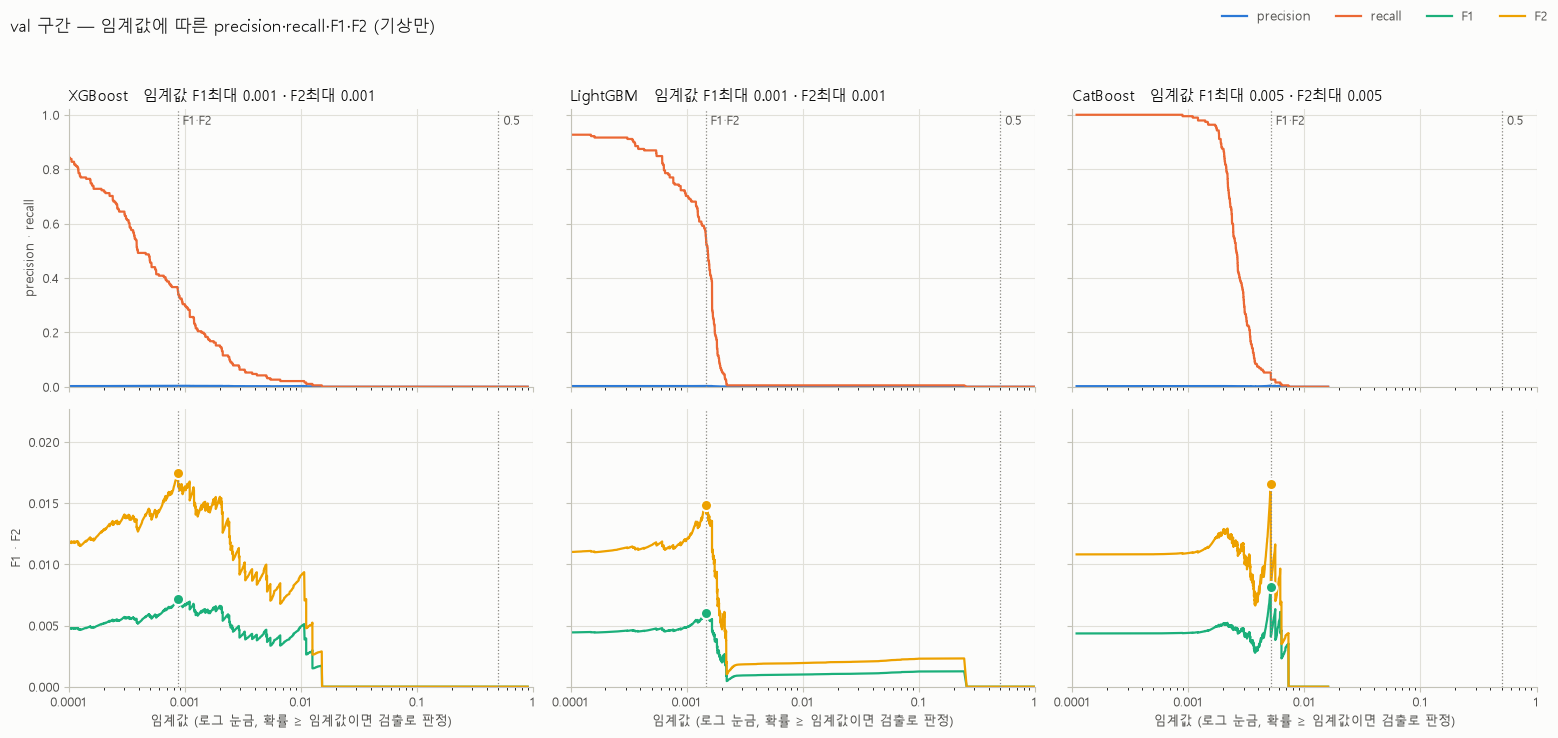

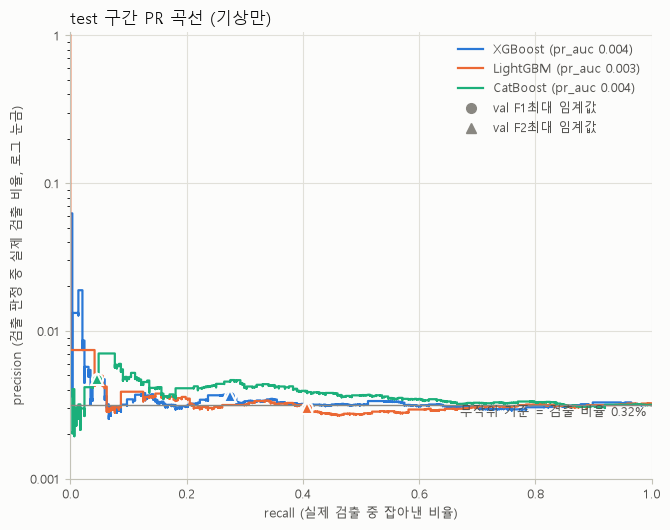

In [8]:
SURFACE, INK, INK2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
MODEL_COLOR = {'XGBoost': '#2a78d6', 'LightGBM': '#eb6834', 'CatBoost': '#1baf7a'}
METRIC_COLOR = {'precision': '#2a78d6', 'recall': '#eb6834', 'F1': '#1baf7a', 'F2': '#eda100'}
PLAIN = FuncFormatter(lambda v, _: f'{v:g}')
FIGURES = {}

def style_axes(ax):
    ax.set_facecolor(SURFACE)
    ax.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=AXIS, labelcolor=INK2, labelsize=9)

fig, axes = plt.subplots(2, len(models), figsize=(5.2 * len(models), 7.4), sharex=True, sharey='row', facecolor=SURFACE)
f_max = 0
for j, name in enumerate(models):
    precision, recall, thr = precision_recall_curve(ys['val'], proba['val'][name])
    precision, recall = precision[:-1], recall[:-1]
    curves = {'precision': precision, 'recall': recall, 'F1': fbeta_curve(precision, recall, 1), 'F2': fbeta_curve(precision, recall, 2)}
    f_max = max(f_max, curves['F1'].max(), curves['F2'].max())
    t1, t2 = thresholds[name]['F1최대'], thresholds[name]['F2최대']
    ax_top, ax_bot = axes[0, j], axes[1, j]
    for ax, ks in [(ax_top, ['precision', 'recall']), (ax_bot, ['F1', 'F2'])]:
        style_axes(ax)
        ax.set_xscale('log')
        for k in ks:
            ax.plot(thr, curves[k], color=METRIC_COLOR[k], linewidth=1.6)
        for t in {t1, t2, 0.5}:
            ax.axvline(t, color=MUTED, linewidth=0.9, linestyle=':')
    for t, k in [(t1, 'F1'), (t2, 'F2')]:
        ax_bot.plot(t, curves[k][np.searchsorted(thr, t)], 'o', markersize=8, color=METRIC_COLOR[k],
                    markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=5)
    if t1 == t2:
        marks = [(t1, 'F1·F2', 'left')]
    else:
        (lo, lo_name), (hi, hi_name) = sorted([(t1, 'F1'), (t2, 'F2')])
        marks = [(lo, lo_name, 'right'), (hi, hi_name, 'left')]
    for t, text, ha in marks + [(0.5, '0.5', 'left')]:
        ax_top.text(t, 1.0, f' {text} ', ha=ha, va='top', color=INK2, fontsize=9)
    ax_top.set_title(f'{name}   임계값 F1최대 {t1:.3f} · F2최대 {t2:.3f}', loc='left', color=INK, fontsize=10.5)
    ax_bot.set_xlabel('임계값 (로그 눈금, 확률 ≥ 임계값이면 검출로 판정)', color=INK2, fontsize=9)
for ax in axes.flat:
    ax.set_xlim(1e-4, 1)
    ax.xaxis.set_major_formatter(PLAIN)
axes[0, 0].set_ylim(0, 1.02)
axes[1, 0].set_ylim(0, f_max * 1.3)
axes[0, 0].set_ylabel('precision · recall', color=INK2, fontsize=9)
axes[1, 0].set_ylabel('F1 · F2', color=INK2, fontsize=9)
fig.legend(handles=[Line2D([], [], color=c, linewidth=1.6, label=k) for k, c in METRIC_COLOR.items()],
           loc='upper right', ncol=4, frameon=False, fontsize=9, labelcolor=INK2)
fig.suptitle('val 구간 — 임계값에 따른 precision·recall·F1·F2 (기상만)', x=0.01, ha='left', color=INK, fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.95))
FIGURES['val_threshold_curves.png'] = fig
plt.show()

fig, ax = plt.subplots(figsize=(6.8, 5.4), facecolor=SURFACE)
style_axes(ax)
ax.set_yscale('log', nonpositive='mask')
pos_rate = ys['test'].mean()
for name in models:
    precision, recall, _ = precision_recall_curve(ys['test'], proba['test'][name])
    ap = average_precision_score(ys['test'], proba['test'][name])
    ax.plot(recall, precision, drawstyle='steps-post', color=MODEL_COLOR[name], linewidth=1.6, label=f'{name} (pr_auc {ap:.3f})')
    for rule, marker in [('F1최대', 'o'), ('F2최대', '^')]:
        row = metrics[(metrics['모델'] == name) & (metrics['구간'] == 'test') & (metrics['임계값 규칙'] == rule)].iloc[0]
        if row['TP'] > 0:
            ax.plot(row['recall'], row['precision'], marker=marker, markersize=8, linestyle='none',
                    color=MODEL_COLOR[name], markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=5)
ax.axhline(pos_rate, color=MUTED, linewidth=1)
ax.text(0.99, pos_rate, f'무작위 기준 = 검출 비율 {pos_rate:.2%}', transform=ax.get_yaxis_transform(), ha='right', va='top', color=INK2, fontsize=9)
ax.set_xlim(0, 1)
ax.set_ylim(1e-3, 1.05)
ax.yaxis.set_major_formatter(PLAIN)
ax.set_xlabel('recall (실제 검출 중 잡아낸 비율)', color=INK2, fontsize=9)
ax.set_ylabel('precision (검출 판정 중 실제 검출 비율, 로그 눈금)', color=INK2, fontsize=9)
ax.set_title('test 구간 PR 곡선 (기상만)', loc='left', color=INK, fontsize=12)
ax.legend(handles=ax.get_legend_handles_labels()[0] + [
    Line2D([], [], marker='o', linestyle='none', color=MUTED, markersize=7, label='val F1최대 임계값'),
    Line2D([], [], marker='^', linestyle='none', color=MUTED, markersize=7, label='val F2최대 임계값')],
    frameon=False, fontsize=9, labelcolor=INK2, loc='upper right')
fig.tight_layout()
FIGURES['test_pr_curve.png'] = fig
plt.show()

## 7. 어떤 칼럼을 썼나 — 변수별·날짜 구간별 중요도

모델이 나무를 나눌 때 쓴 칼럼을 묶음별 비율(%)로 본다(원인이 아니라 "얼마나 잘 갈랐나"). XGBoost `total_gain` · LightGBM `gain` · CatBoost 기본 중요도.
- 위 표: 17개 변수별 합
- 아래 표: 날짜 구간별 합 (D-1~7 · D-8~30 · D-31~60 · D-61~100)

In [9]:
score = models['XGBoost'].get_booster().get_score(importance_type='total_gain')
IMPORTANCE = pd.DataFrame({
    'XGBoost': [score.get(f'f{i}', 0.0) for i in range(len(FEATURES))],
    'LightGBM': models['LightGBM'].booster_.feature_importance(importance_type='gain').astype(float),
    'CatBoost': models['CatBoost'].get_feature_importance().astype(float)}, index=FEATURES)
IMPORTANCE = IMPORTANCE / IMPORTANCE.sum() * 100
ko = dict(WX_VARS)
var_of = IMPORTANCE.index.map(lambda c: ko[c.rsplit('_d', 1)[0]])
lag_of = IMPORTANCE.index.map(lambda c: int(c.rsplit('_d', 1)[1]))
BY_VAR = IMPORTANCE.groupby(var_of).sum().sort_values('XGBoost', ascending=False)
BY_LAG = IMPORTANCE.groupby(pd.cut(lag_of, [0, 7, 30, 60, 100], labels=['D-1~7', 'D-8~30', 'D-31~60', 'D-61~100'])).sum()
display(BY_VAR.round(2))
display(BY_LAG.round(2))
print('모델별 중요도 상위 5칼럼:', {m: IMPORTANCE[m].sort_values(ascending=False).head(5).round(2).to_dict() for m in models})

,XGBoost,LightGBM,CatBoost
이산화질소,28.93,8.88,11.63
토양수분,18.94,4.92,9.40
최대풍속,9.14,9.05,8.39
평균풍속,7.89,12.20,8.86
일산화탄소,6.48,10.04,10.35
일사량,5.92,6.09,7.76
일조시간,5.80,5.56,4.47
강수량,5.01,8.70,6.33
최고기온,3.79,5.03,5.15
아황산가스,2.86,1.72,6.47


,XGBoost,LightGBM,CatBoost
D-1~7,3.60,15.39,6.08
D-8~30,18.54,35.72,21.84
D-31~60,32.76,19.04,28.62
D-61~100,45.11,29.86,43.46


모델별 중요도 상위 5칼럼: {'XGBoost': {'no2_d093': 20.64, 'soil_moist_d041': 16.76, 'no2_d019': 2.49, 'max_wind_d020': 2.15, 'max_temp_d022': 1.74}, 'LightGBM': {'avg_temp_d027': 6.89, 'avg_wind_d023': 4.96, 'rain_d028': 2.72, 'co_d006': 1.66, 'co_d027': 1.53}, 'CatBoost': {'no2_d093': 1.05, 'soil_moist_d098': 0.69, 'soil_moist_d021': 0.69, 'avg_wind_d082': 0.65, 'sunshine_d078': 0.65}}


## 8. MLflow 에 기록

`5_품목만` 과 같은 구조: 부모 run `6_기상만` 1개 + 자식 run 9개(이름 `6_기상만 / 모델 / 규칙`). 지표 이름은 `2_바로학습` 과 같다(`val_`·`test_` + accuracy·precision·recall·f1·f2·roc_auc·pr_auc·TP·FN·FP·TN·n_total·n_pos·n_pred_pos, `threshold`, `fit_seconds`). artifacts: 그림 2개, `metrics.csv`, `config.json`, `predictions.parquet`, `importance.csv`·`importance_by_var.csv`·`importance_by_lag.csv`. `LOG_TO_MLFLOW = False` 면 기록하지 않는다.

In [10]:
INPUT = '기상·대기 17변수 × D-1~D-100 (1,700칼럼)'
def model_params(name, model):
    return model.get_all_params() if name == 'CatBoost' else model.get_params()
def file_mtime(path):
    return datetime.fromtimestamp(Path(path).stat().st_mtime).isoformat(timespec='seconds')

parent_params = {
    'input': INPUT,
    'data.X': str(X_path), 'data.X_mtime': file_mtime(X_path), 'data.y': str(y_path), 'data.y_mtime': file_mtime(y_path),
    'data.join_dir': str(JOIN_DIR), 'data.join_mtime': file_mtime(JOIN_DIR / 'wx_avg_temp.parquet'),
    **{f'split.{r["구간"]}': f'{r["시작일"]}~{r["종료일"]} | {r["행 수"]:,}행 | 검출 {r["검출(1)"]:,}건' for r in split_summary.to_dict('records')},
    'n_features': len(FEATURES), 'features.wx_vars': json.dumps([v for v, _ in WX_VARS]),
    'features.wx_lags': f'D-1~D-{LAG_DAYS} (<변수>_d001 = 기준일 전날)',
    'join': '3_기상조인_후_학습 4절 조인 결과 그대로 (국내 가까운 관측소 3곳 평균, 해외 제조업소 좌표)',
    'seed': SEED, **{f'device.{k}': v for k, v in DEVICE.items()},
    'tuning': '없음 (라이브러리 기본값)', 'imbalance': '없음', 'early_stopping': '없음',
    'threshold_rules': '0.5 / val F1최대 / val F2최대 (판정: 확률 >= 임계값)',
}
config = {'params': parent_params, 'split': split_summary.astype({'시작일': str, '종료일': str}).to_dict('records'),
          'features': FEATURES, 'thresholds': thresholds, 'fit_seconds': fit_seconds,
          'key_params': {n: key_params(n, m) for n, m in models.items()},
          'hyperparameters': {n: model_params(n, m) for n, m in models.items()},
          'libraries': {'python': sys.version.split()[0], 'pandas': pd.__version__, 'numpy': np.__version__,
                        'scikit-learn': sklearn.__version__, 'xgboost': xgb.__version__, 'lightgbm': lgb.__version__,
                        'catboost': cb.__version__, 'mlflow': mlflow.__version__}}
pred_out = pd.concat([pd.DataFrame({KEY_COL: X[KEY_COL].to_numpy()[ROWS[s]], '구간': s, DATE_COL: X[DATE_COL].to_numpy()[ROWS[s]],
                                    'y': ys[s].to_numpy(), **{f'p_{n}': proba[s][n].to_numpy() for n in models}})
                      for s in ['val', 'test']], ignore_index=True)
METRIC_KEYS = {c: c for c in SCORE_COLS + ['TP', 'FN', 'FP', 'TN']}
METRIC_KEYS.update({'전체 건수': 'n_total', '실제 검출': 'n_pos', '예측 양성 수': 'n_pred_pos'})
BOM = chr(0xFEFF)
NOTEBOOK = r'리스테리아ML\EXP\1\6_기상만.ipynb'
STAGE = '베이스라인 — 기상만 (기상·대기 1,700칼럼, 모델 3개 기본값)'

if LOG_TO_MLFLOW:
    with mlflow.start_run(run_name=RUN_NAME) as parent:
        mlflow.set_tags({'notebook': NOTEBOOK, 'stage': STAGE, 'mlflow.note.content': STAGE})
        mlflow.log_params(parent_params)
        for fname, fig in FIGURES.items():
            mlflow.log_figure(fig, f'figures/{fname}')
        mlflow.log_text(BOM + metrics.to_csv(index=False), 'metrics.csv')
        mlflow.log_dict(config, 'config.json')
        mlflow.log_text(BOM + IMPORTANCE.reset_index(names='feature').to_csv(index=False), 'importance.csv')
        mlflow.log_text(BOM + BY_VAR.reset_index(names='변수').to_csv(index=False), 'importance_by_var.csv')
        mlflow.log_text(BOM + BY_LAG.reset_index(names='날짜 구간').to_csv(index=False), 'importance_by_lag.csv')
        with tempfile.TemporaryDirectory() as tmp:
            p = Path(tmp) / 'predictions.parquet'
            pred_out.to_parquet(p, index=False)
            mlflow.log_artifact(str(p))
        for name, model in models.items():
            hp = {f'hp.{k}': v for k, v in model_params(name, model).items()}
            for rule, t in thresholds[name].items():
                with mlflow.start_run(run_name=f'{RUN_NAME} / {name} / {rule}', nested=True):
                    mlflow.set_tags({'notebook': NOTEBOOK, 'stage': STAGE, 'model': name, 'threshold_rule': rule})
                    mlflow.log_params({'input': INPUT, 'model': name, 'threshold_rule': rule, 'threshold': t, 'device': DEVICE[name], **hp})
                    values = {'threshold': t, 'fit_seconds': fit_seconds[name]}
                    for s in ['val', 'test']:
                        row = metrics[(metrics['모델'] == name) & (metrics['구간'] == s) & (metrics['임계값 규칙'] == rule)].iloc[0]
                        values.update({f'{s}_{key}': float(row[col]) for col, key in METRIC_KEYS.items()})
                    mlflow.log_metrics(values)
    PARENT_RUN_ID = parent.info.run_id
    print('기록 완료 — 부모 run', RUN_NAME, PARENT_RUN_ID)
else:
    PARENT_RUN_ID = None
    print('LOG_TO_MLFLOW = False — 이번 실행은 MLflow 에 기록하지 않음')

기록 완료 — 부모 run 6_기상만 e568c4650525443996a833df3c7bdb46


## 9. 실험 1 전체 비교 (test)

MLflow `리스테리아_EXP1` 에서 노트북마다 가장 최근 부모 run 을 읽어, 모델마다 test 지표를 한 표에 놓는다.
- `roc_auc`·`pr_auc` 는 임계값과 무관(확률의 순서만 봄)이라 입력끼리 비교하는 기준이다. pr_auc 무작위 기준 = test 검출 비율 0.00315.
- recall·precision·예측 양성 수는 val F2최대 임계값을 test 에 쓴 결과다.
- 장치: `2_바로학습` CatBoost 는 CPU, `3`·`6` 은 GPU 라 CatBoost 끼리는 장치 차이도 섞인다.

In [11]:
NAMES = {'4_월만': '월 1칼럼(비율표)', '5_품목만': '품목 1칼럼(비율표)', '2_바로학습': 'LIMS 5칼럼',
         '6_기상만': '기상·대기 1,700칼럼', '3_기상조인_후_학습': 'LIMS 5 + 식품 3(값 표기 3) + 기상·대기 1,700칼럼'}
allruns = mlflow.search_runs(experiment_names=[MLFLOW_EXPERIMENT], order_by=['attributes.start_time DESC'])
parents = allruns[allruns['tags.mlflow.parentRunId'].isna()]
rows = []
for nb_name, desc in NAMES.items():
    p = parents[parents['tags.mlflow.runName'] == nb_name]
    if p.empty:
        continue
    pid = p.iloc[0]['run_id']
    kids = allruns[(allruns['tags.mlflow.parentRunId'] == pid) & (allruns['params.threshold_rule'] == 'F2최대')]
    for _, k in kids.iterrows():
        rows.append({'노트북': nb_name, '입력': desc, '모델': k['params.model'],
                     '장치': k.get('params.device') if isinstance(k.get('params.device'), str) else '',
                     'test roc_auc': k['metrics.test_roc_auc'], 'test pr_auc': k['metrics.test_pr_auc'],
                     'F2최대 recall': k['metrics.test_recall'], 'F2최대 precision': k['metrics.test_precision'],
                     'F2최대 예측 양성 수': int(k['metrics.test_n_pred_pos']),
                     '기록 시각': p.iloc[0]['start_time'].tz_convert('Asia/Seoul').strftime('%m-%d %H:%M')})
EXP1_TABLE = pd.DataFrame(rows)
display(EXP1_TABLE.round(4))
if PARENT_RUN_ID:
    with mlflow.start_run(run_id=PARENT_RUN_ID):
        mlflow.log_text(BOM + EXP1_TABLE.to_csv(index=False), 'exp1_comparison.csv')

,노트북,입력,모델,장치,test roc_auc,test pr_auc,F2최대 recall,F2최대 precision,F2최대 예측 양성 수,기록 시각
0,4_월만,월 1칼럼(비율표),월별비율,,0.5295,0.0033,0.3589,0.0035,29170,10-01 17:20
1,5_품목만,품목 1칼럼(비율표),품목별비율,,0.6638,0.0068,0.1742,0.0103,4835,10-01 17:20
2,2_바로학습,LIMS 9칼럼,CatBoost,CPU,0.7551,0.0132,0.2230,0.0260,2466,10-01 17:10
3,2_바로학습,LIMS 9칼럼,LightGBM,cpu,0.7651,0.0145,0.0418,0.0284,423,10-01 17:10
4,2_바로학습,LIMS 9칼럼,XGBoost,cuda,0.7236,0.0102,0.0523,0.0264,569,10-01 17:10
5,6_기상만,"기상·대기 1,700칼럼",CatBoost,GPU,0.5379,0.0038,0.0453,0.0047,2754,10-01 17:24
6,6_기상만,"기상·대기 1,700칼럼",LightGBM,cpu,0.4827,0.0033,0.4077,0.0030,39132,10-01 17:24
7,6_기상만,"기상·대기 1,700칼럼",XGBoost,cuda,0.4991,0.0037,0.2753,0.0036,21781,10-01 17:24
8,3_기상조인_후_학습,"LIMS 9 + 식품 3(값 표기 3) + 기상·대기 1,700칼럼",CatBoost,GPU,0.7430,0.0160,0.0174,0.0327,153,10-01 17:20
9,3_기상조인_후_학습,"LIMS 9 + 식품 3(값 표기 3) + 기상·대기 1,700칼럼",LightGBM,cpu,0.6935,0.0066,0.0488,0.0069,2039,10-01 17:20


## 10. 결론 (2026-10-01 재실행, MLflow run `6_기상만`)

2026-10-01 에 기상 조인 결과가 바뀌어(로마자로 적힌 한국 주소 78행에 국내 관측소 값) 다시 돌렸다. 2026-09-29 실행의 결론은 작업기록 2026-09-29 항목에 있다.

1. **기상·대기 1,700칼럼만으로는 검출을 거의 가려내지 못한다.**
   - test roc_auc 0.483~0.538(무작위 0.5), pr_auc 0.0033~0.0038(무작위 = 검출 비율 0.0032).
2. **입력별 test 비교** (roc_auc / pr_auc, 9절 표)

   | 입력 | roc_auc | pr_auc |
   |---|---|---|
   | 월만 (`4_월만`) | 0.530 | 0.0033 |
   | **기상만 (이 노트북)** | **0.483~0.538** | **0.0033~0.0038** |
   | 품목만 (`5_품목만`) | 0.664 | 0.0068 |
   | LIMS 9칼럼 (`2_바로학습`) | 0.724~0.765 | 0.0102~0.0145 |
   | 전부 (`3_기상조인_후_학습`) | 0.687~0.743 | 0.0066~0.0160 |

   기상만은 월만과 비슷하고, 품목만에도 못 미친다.
3. **F2최대 임계값의 recall 은 가려낸 결과가 아니다.** LightGBM 은 test 의 43%(39,132건), XGBoost 는 24%(21,781건)를 검출로 판정해 recall 이 40.8%·27.5% 로 나왔다. precision 은 0.3~0.4% 로 무작위 수준이다. CatBoost 는 2,754건 판정에 13건 적중(recall 4.5%)이다.
4. **중요도(7절, 칼럼마다 모델이 나무를 가를 때 쓴 몫 — 모델별 합 100%)**
   - XGBoost 는 1,700칼럼 중 `no2_d093`(93일 전 이산화질소) 한 칼럼이 20.6%, `soil_moist_d041`(41일 전 토양수분)이 16.8% 다. 1,700칼럼이 똑같이 나눠 가지면 한 칼럼 몫은 0.06% 다.
   - LightGBM 은 `avg_temp_d027` 이 6.9% 로 가장 크고, CatBoost 는 가장 큰 칼럼도 1.1% 다.
   - 날짜 구간별 합(D-61~100: XGBoost 45.1% · LightGBM 29.9% · CatBoost 43.5%)은 그 구간의 칼럼 수 비율 40% 와 크게 다르지 않다.
   - 딱 하루 값 한두 칼럼에 기대는 모양이라 train 의 일부 시료를 우연히 가르는 칼럼을 잡은 과적합으로 보인다(추정). test roc_auc 0.50 과도 맞는다.
5. **해석**: 하루 값 100일 × 17변수를 그대로 넣고 튜닝하지 않는 방식으로는 기상에서 신호를 찾지 못했다. 다만 기상을 붙인 날짜·장소가 제조 시점·제조 장소인지 확인되지 않는 행이 검출의 대부분이라(작업기록 2026-10-01), "기상이 무관하다"는 결론은 아니다.